# F26-07 | Phase 3: Sentence-Role Classification in Medical Abstracts
**Bio_ClinicalBERT vs. Classical ML (TF-IDF + Logistic Regression / Random Forest / XGBoost) on PubMed 20k RCT**

Group F26-07: Azan Wasty (24L-2557), Nauman Iqbal (24L-2565), Afras Shahnawaz (24L-2547) | Instructor: Hajra Waheed

**Task:** given one abstract sentence, predict its role: `BACKGROUND`, `OBJECTIVE`, `METHODS`, `RESULTS`, `CONCLUSIONS`.

**Pipeline:** raw `.txt` -> parsed DataFrame -> TF-IDF / tokenizer -> model -> predictions -> metrics -> significance tests.

### How this notebook follows the proposal
| Proposal item | Where |
|---|---|
| Classical baselines: Logistic Regression, Random Forest, XGBoost on TF-IDF of cleaned sentence text | Section 4 |
| Bio_ClinicalBERT via HuggingFace Trainer (max len 128, batch 32, 5 epochs, lr 2e-5) | Section 5 |
| Metrics: Accuracy, Weighted F1, Macro F1, Cohen's Kappa, confusion matrices | Sections 4-6 |
| RQ1: accuracy of classical models | Section 6 |
| RQ2: statistical significance (McNemar + paired bootstrap) | Section 7 |
| RQ3: accuracy vs. efficiency (training time, inference cost) | Section 6 |
| Out of scope: position / neighbouring-sentence features | Models use sentence text only. One clearly labelled **optional extension** (Section 4.3) shows what position adds. |

> Runtime note: enable a GPU (Runtime -> Change runtime type -> T4) before running Section 5. The full 5-epoch run on all 180k sentences takes roughly 1.5 to 2 hours on a T4. See the `TRAIN_SUBSAMPLE` switch in Section 5 if your session is limited.

## 1. Setup

In [3]:
%pip install -q transformers accelerate xgboost

In [4]:
import os, re, time, random, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from scipy.sparse import hstack, csr_matrix
from scipy.stats import binomtest
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score,
                             classification_report, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
sns.set_theme(style="whitegrid")

HAS_GPU = torch.cuda.is_available()
print("GPU available:", HAS_GPU, "|", torch.cuda.get_device_name(0) if HAS_GPU else "CPU only")

# Output folder (checkpoints, metrics, predictions). Uses Google Drive on Colab so a disconnect does not lose progress.
OUT_DIR = "./outputs"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/F26-07_outputs"
except ImportError:
    pass
os.makedirs(OUT_DIR, exist_ok=True)
print("Outputs go to:", OUT_DIR)

# Dataset: public PubMed RCT repository (cloned fresh, so every group member can run this)
REPO = "/content/pubmed-rct" if os.path.exists("/content") else "./pubmed-rct"
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/Franck-Dernoncourt/pubmed-rct.git", REPO], check=True)
DATA_DIR = f"{REPO}/PubMed_20k_RCT"
print("Files found:", os.listdir(DATA_DIR))

GPU available: True | Tesla T4
Mounted at /content/drive
Outputs go to: /content/drive/MyDrive/F26-07_outputs
Files found: ['train.txt', 'dev.txt', 'test.txt']


## 2. Data loading and parsing
Same parser as Phase 2, applied to all three official splits (`train`, `dev`, `test`). The parser handles the raw format (`###ID`, then `LABEL<TAB>sentence`) and keeps the last abstract in a file even without a trailing blank line.

**Cleaning (kept light on purpose, as in Phase 2):** whitespace is normalised. Numbers, punctuation and stopwords are kept, because they are strong cues (numbers for RESULTS, tense words such as "was" / "will" for METHODS vs RESULTS). The raw sentence goes to the transformer; the whitespace-normalised sentence goes to TF-IDF (which lowercases it).

In [5]:
LABELS = ["BACKGROUND", "OBJECTIVE", "METHODS", "RESULTS", "CONCLUSIONS"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}   # fixed mapping, used everywhere
ID2LABEL = {i: l for l, i in LABEL2ID.items()}

def _flush(abstract_id, current, rows):
    n = len(current)
    for i, (label, text) in enumerate(current):
        rows.append({"abstract_id": abstract_id, "label": label, "text": text,
                     "line_number": i, "total_lines": n, "line_length": len(text)})

def parse_pubmed_rct(filepath):
    rows, abstract_id, current = [], None, []
    with open(filepath, "r", encoding="utf-8") as f:
        for raw in f:
            line = raw.strip()
            if line.startswith("###"):
                if current: _flush(abstract_id, current, rows)
                abstract_id, current = line[3:], []
            elif line == "":
                if current: _flush(abstract_id, current, rows)
                current = []
            else:
                parts = line.split("\t", 1)
                if len(parts) == 2:
                    current.append((parts[0], parts[1]))
    if current: _flush(abstract_id, current, rows)
    return pd.DataFrame(rows)

def clean_text(s):
    return re.sub(r"\s+", " ", s).strip()

def prepare(df):
    df = df.copy()
    df["label_id"] = df["label"].map(LABEL2ID)
    df["text_clean"] = df["text"].map(clean_text)
    df["relative_position"] = df["line_number"] / df["total_lines"]
    return df

train_df = prepare(parse_pubmed_rct(f"{DATA_DIR}/train.txt"))
dev_df   = prepare(parse_pubmed_rct(f"{DATA_DIR}/dev.txt"))
test_df  = prepare(parse_pubmed_rct(f"{DATA_DIR}/test.txt"))

for name, d in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):>7,} sentences | {d.abstract_id.nunique():>6,} abstracts")

# Sanity checks
assert train_df.label_id.notna().all() and dev_df.label_id.notna().all() and test_df.label_id.notna().all(), "unknown label"
assert not (set(train_df.abstract_id) & set(test_df.abstract_id)), "abstract leakage train/test"
assert not (set(train_df.abstract_id) & set(dev_df.abstract_id)),  "abstract leakage train/dev"
print("\nNo label errors, no abstract overlap between splits.")
print("Duplicate sentences in train:", train_df.text.duplicated().sum())
print("\nTrain class distribution (%):")
print((train_df.label.value_counts(normalize=True)[LABELS] * 100).round(1).to_string())

ytr, ydv, yte = train_df.label_id.values, dev_df.label_id.values, test_df.label_id.values

train: 180,040 sentences | 15,000 abstracts
dev  :  30,212 sentences |  2,500 abstracts
test :  30,135 sentences |  2,500 abstracts

No label errors, no abstract overlap between splits.
Duplicate sentences in train: 1158

Train class distribution (%):
label
BACKGROUND     12.1
OBJECTIVE       7.7
METHODS        33.0
RESULTS        32.2
CONCLUSIONS    15.1


## 3. Evaluation helpers
Every model is scored with **accuracy, weighted F1, macro-F1 and Cohen's kappa** (as in the proposal). Macro-F1 is the primary metric because the classes are imbalanced (OBJECTIVE is under 8%). Models are selected on dev and reported on test.

For RQ3 we record **training time** and **inference time** (feature extraction / tokenisation + prediction on the full test set, reported per 1,000 sentences).

In [6]:
results = {}      # name -> metrics dict
preds_test = {}   # name -> test predictions
preds_dev = {}    # name -> dev predictions
classical_names = []   # text-only classical models (used for model selection and significance tests)

def score(y, p):
    return {"acc": accuracy_score(y, p),
            "weighted_f1": f1_score(y, p, average="weighted"),
            "macro_f1": f1_score(y, p, average="macro"),
            "kappa": cohen_kappa_score(y, p)}

def record(name, p_dv, p_te, train_time, infer_time_test, device, classical=True):
    d, t = score(ydv, p_dv), score(yte, p_te)
    results[name] = {
        "test_acc": t["acc"], "test_weighted_f1": t["weighted_f1"],
        "test_macro_f1": t["macro_f1"], "test_kappa": t["kappa"],
        "dev_macro_f1": d["macro_f1"],
        "train_time_s": round(train_time, 1),
        "infer_s_per_1k": round(infer_time_test / len(yte) * 1000, 3),
        "infer_device": device}
    preds_test[name], preds_dev[name] = p_te, p_dv
    if classical: classical_names.append(name)
    r = results[name]
    print(f"{name:34s} dev macro-F1={r['dev_macro_f1']:.4f} | test acc={r['test_acc']:.4f} "
          f"wF1={r['test_weighted_f1']:.4f} macro-F1={r['test_macro_f1']:.4f} kappa={r['test_kappa']:.4f} "
          f"| train {r['train_time_s']}s | infer {r['infer_s_per_1k']}s/1k")

## 4. Model family 1: classical ML (TF-IDF + classifier)
Models from the proposal, all on **TF-IDF of the sentence text only** (word 1-2 grams, fit on train only):
- **Logistic Regression** (log-loss, optimised with SGD because a full solver is very slow on 200k sparse features).
- **Random Forest** and **XGBoost** (tree models cannot use 200k sparse columns efficiently, so they use a reduced 20k-feature TF-IDF).

Class imbalance is handled with balanced class weights in all three models.

In [7]:
# --- TF-IDF (fit on train only) ---
def build_tfidf(max_features):
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=3,
                           sublinear_tf=True, max_features=max_features)

tfidf_big = build_tfidf(200_000)             # Logistic Regression
Xtr_big = tfidf_big.fit_transform(train_df.text_clean)
Xdv_big = tfidf_big.transform(dev_df.text_clean)
t0 = time.time(); Xte_big = tfidf_big.transform(test_df.text_clean); vec_big_te = time.time() - t0

tfidf_small = build_tfidf(20_000)            # Random Forest, XGBoost
Xtr_small = tfidf_small.fit_transform(train_df.text_clean)
Xdv_small = tfidf_small.transform(dev_df.text_clean)
t0 = time.time(); Xte_small = tfidf_small.transform(test_df.text_clean); vec_small_te = time.time() - t0

print("TF-IDF (200k):", Xtr_big.shape, "| TF-IDF (20k):", Xtr_small.shape)

# Inspect the vocabulary: most discriminative terms per class (from a quick linear model) are shown in Section 6.

TF-IDF (200k): (180040, 200000) | TF-IDF (20k): (180040, 20000)


### 4.1 Logistic Regression, Random Forest, XGBoost

In [8]:
def run_sklearn(name, model, Xtr, Xdv, Xte, vec_time_te, fit_kwargs=None):
    t0 = time.time()
    model.fit(Xtr, ytr, **(fit_kwargs or {}))
    train_time = time.time() - t0
    p_dv = model.predict(Xdv)
    t0 = time.time(); p_te = model.predict(Xte); pred_time = time.time() - t0
    record(name, p_dv, p_te, train_time, vec_time_te + pred_time, "CPU")
    return model

lr = run_sklearn("LogReg (SGD) [text]",
                 SGDClassifier(loss="log_loss", alpha=2e-6, max_iter=30, tol=1e-4,
                               class_weight="balanced", random_state=SEED),
                 Xtr_big, Xdv_big, Xte_big, vec_big_te)

# Random Forest: reduce n_estimators if you hit RAM / time limits on free Colab.
rf = run_sklearn("RandomForest [text]",
                 RandomForestClassifier(n_estimators=100, max_features="sqrt", min_samples_leaf=3,
                                        class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
                 Xtr_small, Xdv_small, Xte_small, vec_small_te)

# XGBoost: uses the GPU when available (much faster on sparse TF-IDF).
sw = compute_sample_weight("balanced", ytr)
xgb = run_sklearn("XGBoost [text]",
                  XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.2, subsample=0.8,
                                colsample_bytree=0.5, tree_method="hist",
                                device="cuda" if HAS_GPU else "cpu",
                                objective="multi:softprob", eval_metric="mlogloss",
                                random_state=SEED, n_jobs=-1),
                  Xtr_small, Xdv_small, Xte_small, vec_small_te, fit_kwargs={"sample_weight": sw})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


LogReg (SGD) [text]                dev macro-F1=0.7733 | test acc=0.8236 wF1=0.8232 macro-F1=0.7630 kappa=0.7630 | train 9.3s | infer 0.073s/1k
RandomForest [text]                dev macro-F1=0.7230 | test acc=0.7722 wF1=0.7726 macro-F1=0.7135 kappa=0.6946 | train 159.8s | infer 0.067s/1k


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [08:42:38] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


XGBoost [text]                     dev macro-F1=0.7392 | test acc=0.7862 wF1=0.7891 macro-F1=0.7305 kappa=0.7149 | train 78.6s | infer 0.045s/1k


### 4.2 Best classical model (chosen on dev, reported on test)

Best classical model on dev: LogReg (SGD) [text] 

              precision    recall  f1-score   support

  BACKGROUND      0.655     0.655     0.655      3621
   OBJECTIVE      0.629     0.599     0.614      2333
     METHODS      0.890     0.918     0.904      9897
     RESULTS      0.899     0.871     0.885      9713
 CONCLUSIONS      0.749     0.765     0.757      4571

    accuracy                          0.824     30135
   macro avg      0.765     0.762     0.763     30135
weighted avg      0.823     0.824     0.823     30135



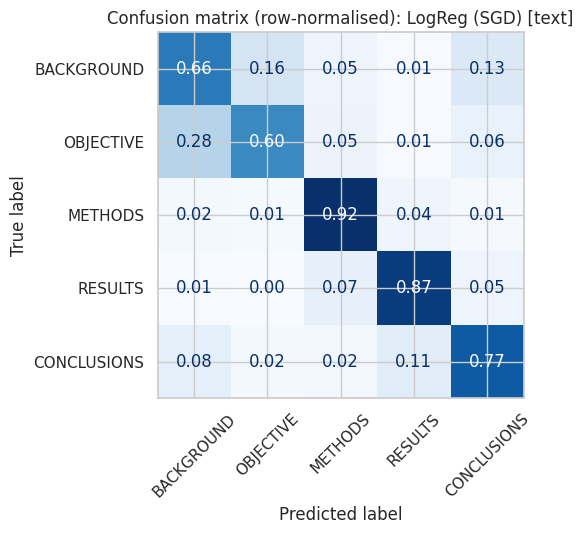

In [9]:
best_classical = max(classical_names, key=lambda k: results[k]["dev_macro_f1"])
print("Best classical model on dev:", best_classical, "\n")
print(classification_report(yte, preds_test[best_classical], target_names=LABELS, digits=3))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(yte, preds_test[best_classical], display_labels=LABELS,
                                        normalize="true", cmap="Blues", xticks_rotation=45,
                                        values_format=".2f", ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix (row-normalised): {best_classical}")
plt.tight_layout(); plt.show()

### 4.3 Optional extension (beyond the proposal scope): what does sentence position add?
The proposal keeps position / neighbouring-sentence features **out of scope**, so all main comparisons above and in Section 7 are text-only. This small extension adds position features to Logistic Regression only, to show how much of any gap could be a feature gap rather than a model gap. Set `RUN_POSITION_EXTENSION = False` to skip it. It is **not** used in the significance tests.

In [10]:
RUN_POSITION_EXTENSION = True

if RUN_POSITION_EXTENSION:
    def pos_feats(df, mu=None, sd=None):
        logl = np.log1p(df.line_length)
        pos_bin = np.minimum((df.relative_position * 10).astype(int), 9).values
        flags = np.c_[(df.line_number == 0), (df.line_number == df.total_lines - 1),
                      df.text.str.contains(r"\d|%", regex=True)].astype(int)
        return np.eye(10)[pos_bin], flags, logl
    p_tr, f_tr, l_tr = pos_feats(train_df); mu_, sd_ = l_tr.mean(), l_tr.std()
    def struct(df):
        p, f, l = pos_feats(df)
        return csr_matrix(np.hstack([p, f, ((l - mu_) / sd_).values[:, None]]))
    Xtr_p = hstack([Xtr_big, struct(train_df)]).tocsr()
    Xdv_p = hstack([Xdv_big, struct(dev_df)]).tocsr()
    Xte_p = hstack([Xte_big, struct(test_df)]).tocsr()
    t0 = time.time()
    lr_pos = SGDClassifier(loss="log_loss", alpha=2e-6, max_iter=30, tol=1e-4,
                           class_weight="balanced", random_state=SEED).fit(Xtr_p, ytr)
    tt = time.time() - t0
    t0 = time.time(); p_te = lr_pos.predict(Xte_p); it = time.time() - t0
    record("LogReg (SGD) [text+position] (ext)", lr_pos.predict(Xdv_p), p_te, tt, vec_big_te + it, "CPU", classical=False)

LogReg (SGD) [text+position] (ext) dev macro-F1=0.8329 | test acc=0.8792 wF1=0.8788 macro-F1=0.8295 kappa=0.8378 | train 11.7s | infer 0.073s/1k


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


## 5. Model family 2: Bio_ClinicalBERT (HuggingFace Trainer)
**Model:** `emilyalsentzer/Bio_ClinicalBERT` (Alsentzer et al., 2019), BERT further pretrained on clinical text.

**Setup (from the proposal):** sentence-only input, classification head on `[CLS]`, cross-entropy loss, max length 128, batch size 32, **5 epochs**, learning rate 2e-5, linear decay with 6% warmup, weight decay 0.01, fp16 on GPU, model selected by best dev macro-F1 (checkpoint saved every epoch).

**Session limits:** full data (about 180k sentences) x 5 epochs is roughly 28,000 steps. If your Colab session cannot run that long, set `TRAIN_SUBSAMPLE` to e.g. `60_000` (stratified) and say so in the report. Checkpoints go to Drive, so after a disconnect set `RESUME = True` and re-run this section.

In [11]:
from sklearn.model_selection import train_test_split
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)
import math

set_seed(SEED)

BERT_NAME = "emilyalsentzer/Bio_ClinicalBERT"
MAX_LEN, BATCH, EPOCHS, LR = 128, 32, 5, 2e-5
TRAIN_SUBSAMPLE = None      # None = all 180k training sentences; or an int such as 60_000 (stratified)
RESUME = False              # True = continue from the last checkpoint in OUT_DIR after a disconnect

if TRAIN_SUBSAMPLE is None:
    train_bert = train_df
else:
    train_bert, _ = train_test_split(train_df, train_size=TRAIN_SUBSAMPLE, stratify=train_df.label_id, random_state=SEED)
print(f"Transformer training sentences: {len(train_bert):,}")
print("Class share (%):", (train_bert.label.value_counts(normalize=True)[LABELS] * 100).round(1).to_dict())

tok = AutoTokenizer.from_pretrained(BERT_NAME)

class SentenceDataset(torch.utils.data.Dataset):
    def __init__(self, df):
        self.enc = tok(df.text.tolist(), truncation=True, max_length=MAX_LEN)  # padding done per batch
        self.labels = df.label_id.tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item

train_ds, dev_ds = SentenceDataset(train_bert), SentenceDataset(dev_df)
t0 = time.time(); test_ds = SentenceDataset(test_df); tok_time_te = time.time() - t0

sample = train_bert.text.sample(2000, random_state=SEED)
pieces = np.mean([len(tok.tokenize(t)) / max(len(t.split()), 1) for t in sample])
print(f"Avg tokens per whitespace word with this tokenizer: {pieces:.2f}")

Transformer training sentences: 180,040
Class share (%): {'BACKGROUND': 12.1, 'OBJECTIVE': 7.7, 'METHODS': 33.0, 'RESULTS': 32.2, 'CONCLUSIONS': 15.1}


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

Avg tokens per whitespace word with this tokenizer: 1.38


In [14]:
model = AutoModelForSequenceClassification.from_pretrained(
    BERT_NAME, num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID)
print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "macro_f1": f1_score(labels, preds, average="macro")}

steps_per_epoch = math.ceil(len(train_ds) / BATCH)
warmup = int(0.06 * steps_per_epoch * EPOCHS)

args = TrainingArguments(
    output_dir=f"{OUT_DIR}/bio_clinicalbert_ckpt", num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH, per_device_eval_batch_size=64,
    learning_rate=LR, weight_decay=0.01, warmup_steps=warmup,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model="macro_f1",
    fp16=HAS_GPU, seed=SEED, logging_steps=200, report_to="none")

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=dev_ds,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)

t0 = time.time()
trainer.train(resume_from_checkpoint=True if RESUME else None)
bert_train_time = round(time.time() - t0, 1)   # note: if you resumed, this only counts the resumed part
print(f"Training time: {bert_train_time}s")
trainer.save_model(f"{OUT_DIR}/bio_clinicalbert_best")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the chec

Parameters: 108.3M


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.367606,0.331170,0.878293,0.818897
2,0.298562,0.339093,0.880081,0.823848
3,0.238857,0.366413,0.879849,0.825299
4,0.179932,0.416898,0.877698,0.823316
5,0.152189,0.469856,0.871905,0.817035


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training time: 4999.7s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Bio_ClinicalBERT [text]            dev macro-F1=0.8253 | test acc=0.8698 wF1=0.8689 macro-F1=0.8143 kappa=0.8247 | train 4999.7s | infer 1.656s/1k

              precision    recall  f1-score   support

  BACKGROUND      0.701     0.752     0.726      3621
   OBJECTIVE      0.699     0.614     0.654      2333
     METHODS      0.927     0.950     0.938      9897
     RESULTS      0.917     0.923     0.920      9713
 CONCLUSIONS      0.863     0.807     0.834      4571

    accuracy                          0.870     30135
   macro avg      0.821     0.809     0.814     30135
weighted avg      0.869     0.870     0.869     30135



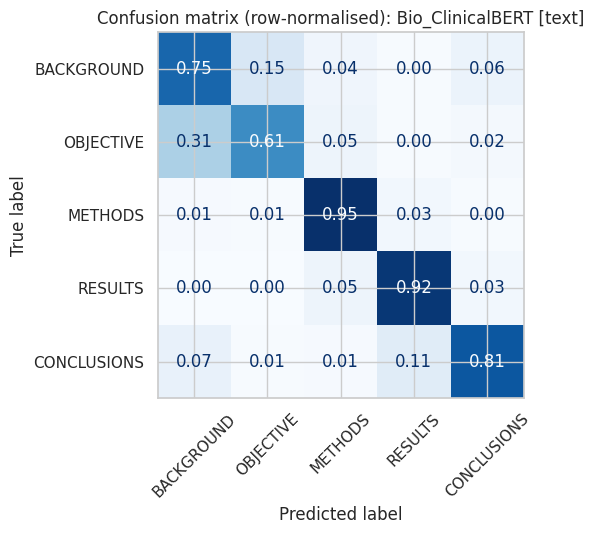

In [15]:
# Evaluate on dev and test (test inference is timed: tokenisation + forward passes)
dev_out = trainer.predict(dev_ds)
t0 = time.time(); test_out = trainer.predict(test_ds); bert_pred_time = time.time() - t0
p_dv, p_te = dev_out.predictions.argmax(-1), test_out.predictions.argmax(-1)

bert_name = "Bio_ClinicalBERT [text]" + ("" if TRAIN_SUBSAMPLE is None else f" [{TRAIN_SUBSAMPLE//1000}k subsample]")
record(bert_name, p_dv, p_te, bert_train_time, tok_time_te + bert_pred_time,
       "GPU" if HAS_GPU else "CPU", classical=False)

print()
print(classification_report(yte, p_te, target_names=LABELS, digits=3))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(yte, p_te, display_labels=LABELS, normalize="true", cmap="Blues",
                                        xticks_rotation=45, values_format=".2f", ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix (row-normalised): {bert_name}")
plt.tight_layout(); plt.show()

## 6. Results summary (RQ1 and RQ3)

,test_acc,test_weighted_f1,test_macro_f1,test_kappa,dev_macro_f1,train_time_s,infer_s_per_1k,infer_device
LogReg (SGD) [text+position] (ext),0.8792,0.8788,0.8295,0.8378,0.8329,11.7,0.073,CPU
Bio_ClinicalBERT [text],0.8698,0.8689,0.8143,0.8247,0.8253,4999.7,1.656,GPU
LogReg (SGD) [text],0.8236,0.8232,0.7630,0.7630,0.7733,9.3,0.073,CPU
XGBoost [text],0.7862,0.7891,0.7305,0.7149,0.7392,78.6,0.045,CPU
RandomForest [text],0.7722,0.7726,0.7135,0.6946,0.7230,159.8,0.067,CPU


,LogReg (SGD) [text],Bio_ClinicalBERT [text]
BACKGROUND,0.655,0.726
OBJECTIVE,0.614,0.654
METHODS,0.904,0.938
RESULTS,0.885,0.920
CONCLUSIONS,0.757,0.834


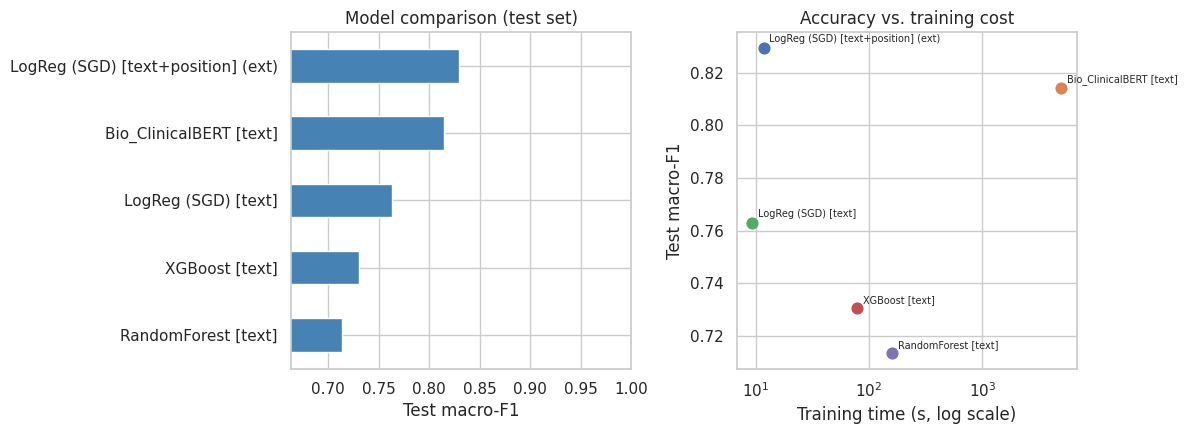

In [16]:
summary = pd.DataFrame(results).T
num_cols = ["test_acc", "test_weighted_f1", "test_macro_f1", "test_kappa", "dev_macro_f1", "train_time_s", "infer_s_per_1k"]
summary[num_cols] = summary[num_cols].astype(float).round(4)
summary = summary[num_cols + ["infer_device"]].sort_values("test_macro_f1", ascending=False)
display(summary)

# Per-class F1: best classical vs Bio_ClinicalBERT
from sklearn.metrics import precision_recall_fscore_support
rows = {}
for nm in [best_classical, bert_name]:
    _, _, f, _ = precision_recall_fscore_support(yte, preds_test[nm], labels=range(len(LABELS)), zero_division=0)
    rows[nm] = f
per_class = pd.DataFrame(rows, index=LABELS).round(3)
display(per_class)

# Accuracy vs. efficiency (RQ3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
summary["test_macro_f1"].sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_xlabel("Test macro-F1"); axes[0].set_title("Model comparison (test set)")
axes[0].set_xlim(max(0, summary.test_macro_f1.min() - 0.05), 1)
for nm, r in summary.iterrows():
    axes[1].scatter(r.train_time_s, r.test_macro_f1, s=60)
    axes[1].annotate(nm, (r.train_time_s, r.test_macro_f1), fontsize=7, xytext=(4, 4), textcoords="offset points")
axes[1].set_xscale("log"); axes[1].set_xlabel("Training time (s, log scale)"); axes[1].set_ylabel("Test macro-F1")
axes[1].set_title("Accuracy vs. training cost")
plt.tight_layout(); plt.show()

In [17]:
# Which words drive the classical model? (RQ1 interpretability / TF-IDF vocabulary inspection)
terms = np.array(tfidf_big.get_feature_names_out())
for i, lab in enumerate(LABELS):
    top = terms[np.argsort(lr.coef_[i])[-8:][::-1]]
    print(f"{lab:12s}: {', '.join(top)}")

BACKGROUND  : is, was to, conducted to, have, has, aim, was designed, are
OBJECTIVE   : compare, to, whether, evaluate, to test, investigate, examine, to compare
METHODS     : were, were compared, will, received, or, included, assessed, provides class
RESULTS     : 001, 05, respectively, 01, showed, 0001, significantly, 95
CONCLUSIONS : should, improved, in, further, our, may, future, was effective


## 7. Statistical significance (RQ2)
Is Bio_ClinicalBERT's difference from each classical model larger than chance? All tests use the **test set predictions** of the text-only models (the position extension is excluded).

1. **McNemar's exact test** on paired correct/incorrect outcomes per sentence.
2. **Paired bootstrap** (1,000 resamples) of the **macro-F1 difference**, resampling whole **abstracts** (sentences in one abstract are not independent). We report the 95% confidence interval.

Because we compare against three classical models, we also show a Bonferroni-adjusted threshold (0.05 / 3). The result comes from a single training seed, so the claim is about this trained model, not about training randomness.

In [18]:
def fast_macro_f1(y, p, k=len(LABELS)):
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    denom = 2 * tp + fp + fn
    return np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0).mean()

def mcnemar_exact(y, p_a, p_b):
    a_ok, b_ok = p_a == y, p_b == y
    n_a_only = int(np.sum(a_ok & ~b_ok)); n_b_only = int(np.sum(~a_ok & b_ok))
    n = n_a_only + n_b_only
    p = binomtest(n_a_only, n, 0.5).pvalue if n > 0 else 1.0
    return n_a_only, n_b_only, p

def paired_bootstrap_diff(y, p_a, p_b, groups, n_boot=1000, seed=SEED):
    # difference = macro_F1(B) - macro_F1(A), resampling abstracts
    rng = np.random.default_rng(seed)
    codes, _ = pd.factorize(groups)
    order = np.argsort(codes, kind="stable")
    bounds = np.r_[0, np.cumsum(np.bincount(codes))]
    idx_by_group = [order[bounds[i]:bounds[i + 1]] for i in range(len(bounds) - 1)]
    G = len(idx_by_group)
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        idx = np.concatenate([idx_by_group[g] for g in rng.integers(0, G, G)])
        diffs[b] = fast_macro_f1(y[idx], p_b[idx]) - fast_macro_f1(y[idx], p_a[idx])
    return np.percentile(diffs, [2.5, 97.5]), diffs

groups_te = test_df.abstract_id.values
p_bert = preds_test[bert_name]
alpha_bonf = 0.05 / len(classical_names)

rows = []
for nm in classical_names:
    a_only, b_only, p = mcnemar_exact(yte, preds_test[nm], p_bert)
    (lo, hi), diffs = paired_bootstrap_diff(yte, preds_test[nm], p_bert, groups_te)
    point = fast_macro_f1(yte, p_bert) - fast_macro_f1(yte, preds_test[nm])
    rows.append({"classical model (A)": nm,
                 "macro-F1 diff (BERT - A)": round(point, 4),
                 "95% CI (abstract bootstrap)": f"[{lo:+.4f}, {hi:+.4f}]",
                 "only A right": a_only, "only BERT right": b_only,
                 "McNemar p": p,
                 f"significant at {alpha_bonf:.4f}?": "yes" if p < alpha_bonf else "no"})
sig = pd.DataFrame(rows)
display(sig)
print("A positive difference whose CI excludes 0 means Bio_ClinicalBERT is significantly better on macro-F1.")

,classical model (A),macro-F1 diff (BERT - A),95% CI (abstract bootstrap),only A right,only BERT right,McNemar p,significant at 0.0167?
0,LogReg (SGD) [text],0.0512,"[+0.0456, +0.0570]",1046,2439,2.290152e-126,yes
1,RandomForest [text],0.1008,"[+0.0943, +0.1070]",1078,4020,0.000000e+00,yes
2,XGBoost [text],0.0838,"[+0.0775, +0.0898]",1092,3611,5.010612e-311,yes


A positive difference whose CI excludes 0 means Bio_ClinicalBERT is significantly better on macro-F1.


In [19]:
# Save everything needed for the report / later phases
summary.to_csv(f"{OUT_DIR}/phase3_metrics.csv")
sig.to_csv(f"{OUT_DIR}/phase3_significance.csv", index=False)
np.savez(f"{OUT_DIR}/phase3_test_predictions.npz", y_true=yte, **{k.replace(" ", "_"): v for k, v in preds_test.items()})
print("Saved metrics, significance table and test predictions to", OUT_DIR)

Saved metrics, significance table and test predictions to /content/drive/MyDrive/F26-07_outputs


## 8. Error analysis

In [20]:
err = test_df.assign(pred=[ID2LABEL[i] for i in preds_test[bert_name]])
err = err[err.label != err.pred]
print(f"{bert_name}: misclassified {len(err):,} of {len(test_df):,} ({len(err)/len(test_df):.1%})")
print("\nMost common confusions (true -> predicted):")
print(err.groupby(["label", "pred"]).size().sort_values(ascending=False).head(6).to_string())

print("\nRandom misclassified examples:")
for _, r in err.sample(8, random_state=SEED).iterrows():
    print(f"[true={r.label:11s} pred={r.pred:11s} pos={r.relative_position:.2f}] {r.text[:200]}")

# Accuracy by position decile (diagnostic only; position is NOT a model input here)
dec = np.minimum((test_df.relative_position * 10).astype(int), 9)
acc_by_pos = pd.DataFrame({
    "classical": pd.Series(preds_test[best_classical] == yte).groupby(dec.values).mean(),
    "Bio_ClinicalBERT": pd.Series(p_bert == yte).groupby(dec.values).mean()}).round(3)
acc_by_pos.index.name = "position decile"
display(acc_by_pos)

Bio_ClinicalBERT [text]: misclassified 3,923 of 30,135 (13.0%)

Most common confusions (true -> predicted):
label        pred      
OBJECTIVE    BACKGROUND    732
BACKGROUND   OBJECTIVE     528
CONCLUSIONS  RESULTS       493
RESULTS      METHODS       442
CONCLUSIONS  BACKGROUND    313
METHODS      RESULTS       295

Random misclassified examples:
[true=CONCLUSIONS pred=BACKGROUND  pos=0.91] Perioperative fluid restriction could effect on fluid distribution and reduce tissue and cellular edema , and further , could reduce postoperative complication rates .
[true=CONCLUSIONS pred=BACKGROUND  pos=0.89] We propose to assess its efficacy in reducing suicide reattempt in the suicide attempter ( SA ) population .
[true=METHODS     pred=RESULTS     pos=0.44] Mean distraction rates were similar between groups ( 0.75 mm/day in the treatment group versus 0.72 mm/day in the control group ; p = 0.24 ) .
[true=OBJECTIVE   pred=BACKGROUND  pos=0.00] Endothelial function is an independent predictor o

,classical,Bio_ClinicalBERT
position decile,,
0,0.670,0.731
1,0.762,0.794
2,0.838,0.878
3,0.873,0.915
4,0.880,0.935
5,0.892,0.946
6,0.887,0.931
7,0.851,0.893
8,0.805,0.849


In [21]:
import joblib
for nm, m in [("logreg", lr), ("random_forest", rf), ("xgboost", xgb)]:
    joblib.dump(m, f"{OUT_DIR}/{nm}.joblib")
joblib.dump(tfidf_big, f"{OUT_DIR}/tfidf_200k.joblib")
joblib.dump(tfidf_small, f"{OUT_DIR}/tfidf_20k.joblib")
print("Saved classical models and vectorisers to", OUT_DIR)

Saved classical models and vectorisers to /content/drive/MyDrive/F26-07_outputs


## 9. Notes and limitations (for the report)
- **Proposal alignment:** classical models are Logistic Regression, Random Forest and XGBoost on TF-IDF text; the transformer is Bio_ClinicalBERT with the proposed settings (max length 128, batch 32, 5 epochs, lr 2e-5). All main comparisons use sentence text only (position features are out of scope).
- **Deviations to state explicitly (if they apply to your run):** if `TRAIN_SUBSAMPLE` is not `None`, say the transformer used a stratified subsample; Random Forest and XGBoost use a 20k-feature TF-IDF while Logistic Regression uses 200k; Logistic Regression is trained with SGD for speed; the position extension (Section 4.3) is an add-on, not part of the proposed scope.
- **Single seed:** all numbers come from one run (seed 42). The significance tests measure sampling uncertainty on the test set, not training-seed variance. Repeated seeds are a Phase 4 item.
- **Efficiency numbers:** classical models run on CPU and Bio_ClinicalBERT on GPU, so inference times are not like-for-like hardware. Report the device column alongside the times.
- **Label noise:** some labels are ambiguous (for example registration numbers labelled `BACKGROUND`, or aims labelled `BACKGROUND` instead of `OBJECTIVE`), which caps achievable accuracy, especially for OBJECTIVE.
- **Scope:** results are for published RCT abstracts and do not transfer directly to clinical notes.